In [37]:
library(tidyverse)
install.packages("janitor", repos = "https://cloud.r-project.org")
install.packages("exactRankTests", repos = "https://cloud.r-project.org")
#Import dataset
wine <- read_csv("winequality-red.csv")

head(wine)

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done

Rows: 1599 Columns: 12
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (12): fixed acidity, volatile acidity, citric acid, residual sugar, chlo...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.8,0.88,0.00,2.6,0.098,25,67,0.9968,3.20,0.68,9.8,5
7.8,0.76,0.04,2.3,0.092,15,54,0.9970,3.26,0.65,9.8,5
11.2,0.28,0.56,1.9,0.075,17,60,0.9980,3.16,0.58,9.8,6
7.4,0.70,0.00,1.9,0.076,11,34,0.9978,3.51,0.56,9.4,5
7.4,0.66,0.00,1.8,0.075,13,40,0.9978,3.51,0.56,9.4,5


## Cleaning the Data

In [38]:
library(janitor)

wine <- wine |>
  clean_names()

names(wine)

[1] "fixed_acidity"        "volatile_acidity"     "citric_acid"         
 [4] "residual_sugar"       "chlorides"            "free_sulfur_dioxide" 
 [7] "total_sulfur_dioxide" "density"              "p_h"                 
[10] "sulphates"            "alcohol"              "quality"

In [39]:
#Count missing values in each column
colSums(is.na(wine))

#Total missing values
sum(is.na(wine))

fixed_acidity     volatile_acidity          citric_acid 
                   0                    0                    0 
      residual_sugar            chlorides  free_sulfur_dioxide 
                   0                    0                    0 
total_sulfur_dioxide              density                  p_h 
                   0                    0                    0 
           sulphates              alcohol              quality 
                   0                    0                    0

[1] 0

## Exploratory Data Analysis

### Summary Statistics for All Variables

In [40]:
#Dataset dimensions
dim(wine)

#Summary statistics
summary(wine)

[1] 1599   12

 fixed_acidity   volatile_acidity  citric_acid    residual_sugar  
 Min.   : 4.60   Min.   :0.1200   Min.   :0.000   Min.   : 0.900  
 1st Qu.: 7.10   1st Qu.:0.3900   1st Qu.:0.090   1st Qu.: 1.900  
 Median : 7.90   Median :0.5200   Median :0.260   Median : 2.200  
 Mean   : 8.32   Mean   :0.5278   Mean   :0.271   Mean   : 2.539  
 3rd Qu.: 9.20   3rd Qu.:0.6400   3rd Qu.:0.420   3rd Qu.: 2.600  
 Max.   :15.90   Max.   :1.5800   Max.   :1.000   Max.   :15.500  
   chlorides       free_sulfur_dioxide total_sulfur_dioxide    density      
 Min.   :0.01200   Min.   : 1.00       Min.   :  6.00       Min.   :0.9901  
 1st Qu.:0.07000   1st Qu.: 7.00       1st Qu.: 22.00       1st Qu.:0.9956  
 Median :0.07900   Median :14.00       Median : 38.00       Median :0.9968  
 Mean   :0.08747   Mean   :15.87       Mean   : 46.47       Mean   :0.9967  
 3rd Qu.:0.09000   3rd Qu.:21.00       3rd Qu.: 62.00       3rd Qu.:0.9978  
 Max.   :0.61100   Max.   :72.00       Max.   :289.00       Max.   :1

### Distribution of Wine Quality

quality,n,percentage
<dbl>,<int>,<dbl>
3,10,0.63
4,53,3.31
5,681,42.59
6,638,39.90
7,199,12.45
8,18,1.13


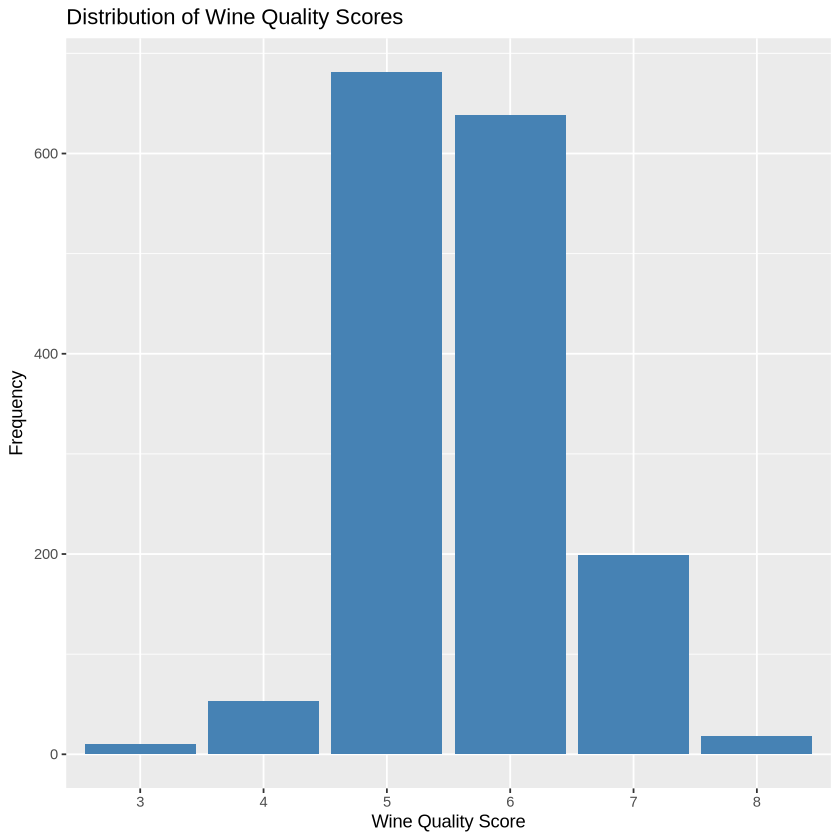

In [41]:
wine |>
  count(quality) |>
  mutate(percentage = round(n / sum(n) * 100, 2))

ggplot(wine, aes(x = factor(quality))) +
  geom_bar(fill = "steelblue") +
  labs(title = "Distribution of Wine Quality Scores",
    x = "Wine Quality Score",
    y = "Frequency")

### Distribution of Input Variables (Wine Characteristics)

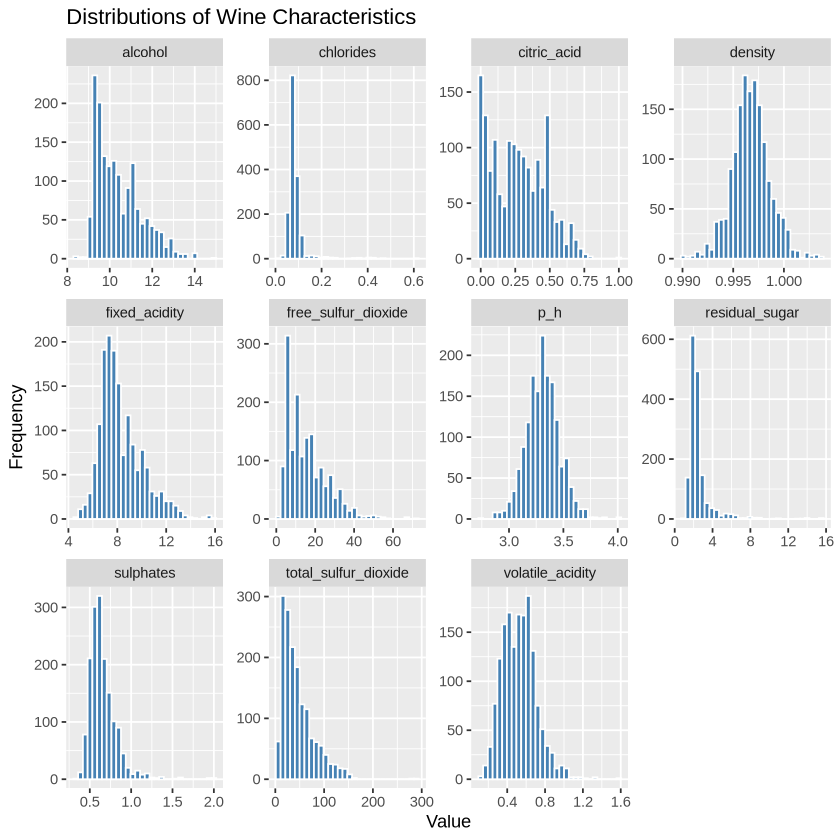

In [42]:
wine |>
  select(-quality) |>
  pivot_longer(cols = everything(),
    names_to = "variable",
    values_to = "value") |>
  ggplot(aes(x = value)) +
  geom_histogram(bins = 30,
    fill = "steelblue",
    color = "white") +
  facet_wrap(~ variable, scales = "free") +
  labs(title = "Distributions of Wine Characteristics",
    x = "Value",
    y = "Frequency") 

### Examining Some Selected Correlation Coeffecients (Pearson)

In [43]:
#Correlation between alcohol and quality
cor(wine$alcohol, wine$quality)

#Correlation between volatile acidity and quality
cor(wine$volatile_acidity, wine$quality)

#Correlation between sulphates and quality
cor(wine$sulphates, wine$quality)

[1] 0.4761663

[1] -0.3905578

[1] 0.2513971

### Creating a Correlation Plot/ HeatMap for all Wine Characteristics

Updating HTML index of packages in '.Library'

Making 'packages.html' ...
 done



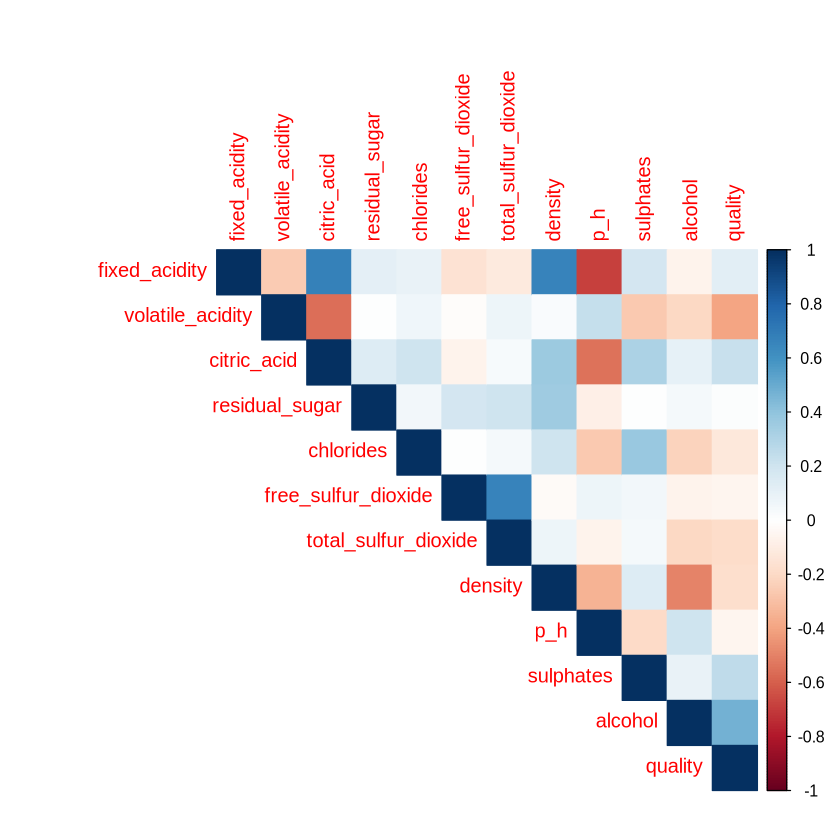

In [53]:
install.packages("corrplot")   
library(corrplot)

cor_matrix <- cor(wine)

corrplot(cor_matrix,
         method = "color",
         type = "upper")

# Daryn's code: Two-samples t-test


Higher-rated  Lower-rated 
         855          744 

quality_group,n,mean_alcohol,sd_alcohol,median_alcohol
<chr>,<int>,<dbl>,<dbl>,<dbl>
Higher-rated,855,10.855029,1.1061093,10.8
Lower-rated,744,9.926478,0.7580065,9.7



	Welch Two Sample t-test

data:  alcohol by quality_group
t = 19.782, df = 1516.8, p-value < 2.2e-16
alternative hypothesis: true difference in means between group Higher-rated and group Lower-rated is not equal to 0
95 percent confidence interval:
 0.836479 1.020622
sample estimates:
mean in group Higher-rated  mean in group Lower-rated 
                 10.855029                   9.926478 


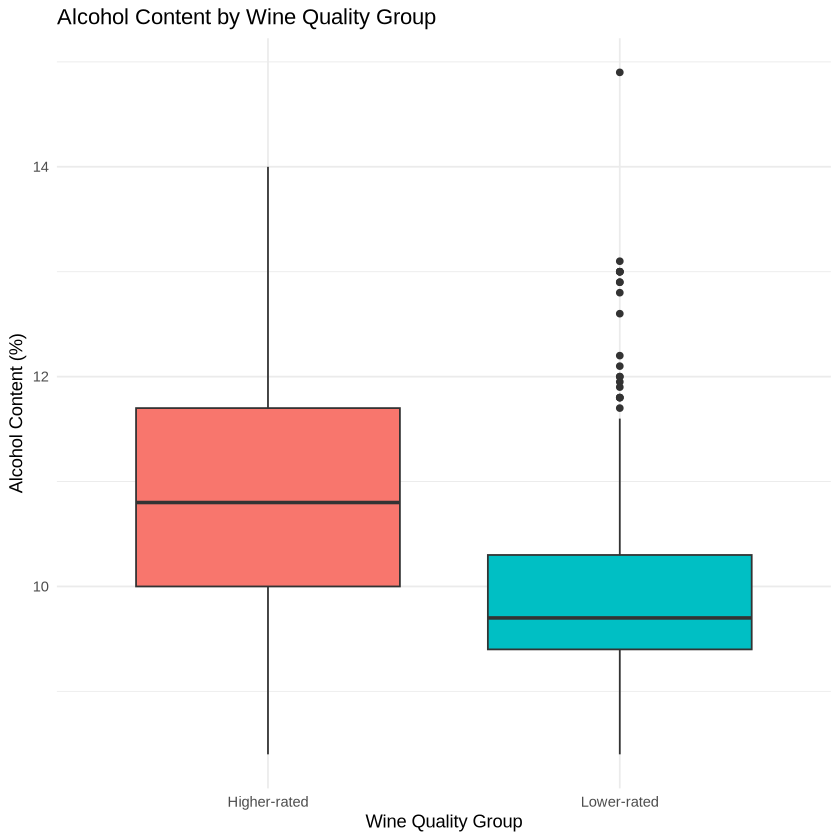

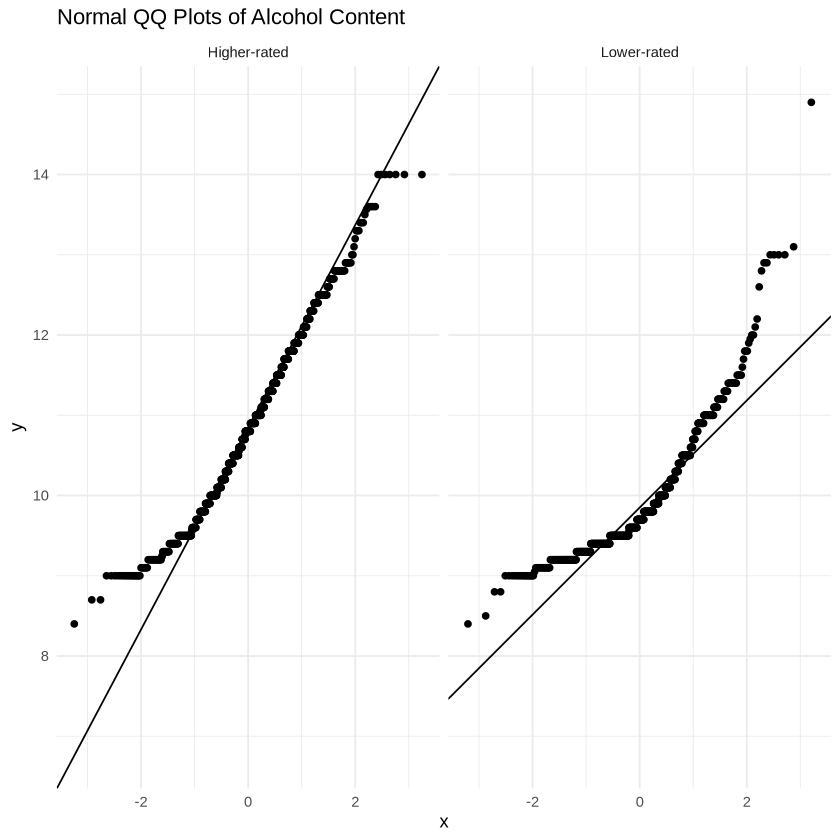

In [58]:
# Recall: QQ plot suggests non-normal distribution

# create quality groups
wine <- wine |>
  mutate(
    quality_group = if_else(
      quality >= 6,
      "Higher-rated",
      "Lower-rated"
    )
  )

# check group sizes
table(wine$quality_group)


# summary statistics by quality group
wine |>
  group_by(quality_group) |>
  summarise(
    n = n(),
    mean_alcohol = mean(alcohol),
    sd_alcohol = sd(alcohol),
    median_alcohol = median(alcohol)
  )


# two-sample t-test
t_test_result <- t.test(
  alcohol ~ quality_group,
  data = wine,
  alternative = "two.sided",
  var.equal = FALSE,
  conf.level = 0.95
)

t_test_result



# boxplot: check differences and outliers
ggplot(wine, aes(x = quality_group, y = alcohol,
                 fill = quality_group)) +
  geom_boxplot() +
  labs(
    title = "Alcohol Content by Wine Quality Group",
    x = "Wine Quality Group",
    y = "Alcohol Content (%)"
  ) +
  theme_minimal() +
  theme(legend.position = "none")

# QQ plots: assess normality within each group
ggplot(wine, aes(sample = alcohol)) +
  stat_qq() +
  stat_qq_line() +
  facet_wrap(~ quality_group) +
  labs(
    title = "Normal QQ Plots of Alcohol Content"
  ) +
  theme_minimal()

# Henry's code: permutation test

## Is there a significant difference in mean alcohol content between higher-rated and lower-rated red wines?
In the previous EDA section, we have concluded that the original data does not follow a perfectly normal distribution, thus there is limitation on two-sample t-tests. Now, we apply a permutation test as an alternative approach. This type of test does not require normality, instead, it uses permutation distributions to assess statistical significance. We can compare its results with Welch's two-sample t-tests to see if both methods give similar conclusions.

We will use a two-sample permutation test to compare the alcohol content between higher-rated wines and lower-rated wines.
A permutation test works by counting all possible ways to permute the data and then compute the test statistics for each arrangement.

We used the same groups as the two-sample t-test, where quality >= 6 is considered "Higher-rated" and quality < 6 is considered "Lower-rated". There are 855 higher-rated wines and 744 lower-rated wines. 

In [68]:
# Recall: quality groups
wine <- wine |>
  mutate(quality_group = if_else(
      quality >= 6,
      "Higher-rated",
      "Lower-rated"))



## Hypotheses
We use a two-sided permutation test to determine whether alcohol contents differ between higher and lower rated wines.


**H₀ :** The population mean alcohol content is equal between higher-rated and lower-rated red wines.

$$
H_0: \mu_H = \mu_L
$$

**H₁ :** The population mean alcohol content is different between higher-rated and lower-rated red wines.

$$
H_1: \mu_H \neq \mu_L
$$

**Where:**

- $\mu_H$: Population mean alcohol content of higher-rated red wines.
- $\mu_L$: Population mean alcohol content of lower-rated red wines.


We set `paired = FALSE` because the groups are independent, and `mu = 0` because the null hypothesis assumes no difference between the groups. We used `exact = FALSE` to calculate the p-value using an asymptotic approximation.

In [69]:
library(exactRankTests)
higher_rated <- wine$alcohol[wine$quality_group == "Higher-rated"]
lower_rated <- wine$alcohol[wine$quality_group == "Lower-rated"]

# Check group sizes
table(wine$quality_group)

# Two-sample permutation test
perm_test_result <- perm.test(
  higher_rated,
  lower_rated,
  paired = FALSE,
  alternative = "two.sided",
  mu = 0,
  exact = FALSE,
  conf.int = FALSE
)
perm_test_result


Higher-rated  Lower-rated 
         855          744 


	Asymptotic 2-sample Permutation Test

data:  higher_rated and lower_rated
T = 9281, p-value < 2.2e-16
alternative hypothesis: true mu is not equal to 0


## Interpretation

The permutation test gives a p-value smaller than 2.2 × 10⁻¹⁶, which is much smaller than the significance level of 0.05. Therefore, we reject the null hypothesis.
There is strong evidence that the alcohol content distributions differ between higher-rated and lower-rated red wines. This result is consistent with the conclusion of the two-sample t-test.

## Assumptions and Limitations

- Assumption: Permutation tests doe not require normality. However, it assumes observations are independent and interchangeable.
- Limitation: According to previous EDA, we can tell that the two groups have different SDs (1.106 and 0.758), which means that the two grouops have different variance in data, thus may affect the exchangeability assumption.